In [13]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#In this code we install and fool around with the gymnasium environment
#Jeremy Kedziora
#17 Nov 2025
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@

#In order to set up the kernel used in this notebook I created a virtual env by running the following at the command line:
#conda create -n py_Gym python=3.10
#conda activate py_Gym
#pip install ale-py
#pip install autorom[accept-rom-license]
#AutoROM --accept-license
#pip install "gymnasium[atari,accept-rom-license]" --force-reinstall
#pip install torch
#conda install matplotlib
#conda install ipykernel
#python -m ipykernel install --user --name=py_Gym --display-name="Python py_Gym"

#documentation for the space invaders environment is here: https://ale.farama.org/environments/space_invaders/


In [2]:
%pip install gymnasium
%pip install ale_py
%pip install cv2

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
ERROR: Could not find a version that satisfies the requirement cv2 (from versions: none)
ERROR: No matching distribution found for cv2
Note: you may need to restart the kernel to use updated packages.


In [3]:
#@@@@@@@@@@@@@@@@@@@@@@@
#import useful libraries
#@@@@@@@@@@@@@@@@@@@@@@@
import gymnasium as gym
#from gymnasium.wrappers import AtariPreprocessing
import numpy as np
import ale_py
import cv2

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.distributions import Categorical

torch.autograd.set_detect_anomaly(True)


In [4]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#A function to set up the environment with automated preprocessing
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
def make_env(env_name = "ALE/SpaceInvaders-v5"):
    """A function to set up the environment
        Takes:
            env_name -- string, the name of the environment in ALE
        Returns:
            an environment set up with standard DQN atari preprocessing (grayscale 84x84, frame_skip=4)
    """
    env = gym.make(env_name, render_mode="rgb_array",frameskip=1)    #make the environment
    env = gym.wrappers.AtariPreprocessing(
        env,
        screen_size=84,
        grayscale_obs=True,
        frame_skip=4,
        scale_obs=True, #note these could also be normalized in the network
        terminal_on_life_loss=False)    #set up the preprocessing choices
    return env

#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
def reward_processing(env_reward,done,truncated):
    if not done and not truncated:
        env_reward += 0.25
    if not done and truncated:
        env_reward += 100
    return env_reward


In [5]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#specify the deep learning model architecture for the actor and critic -- in this example they share input layers
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
class CNNActorCritic(nn.Module):
    def __init__(self, config):
        super().__init__()
        # Classic Atari-style conv net

        #set up the convolutional layers
        self.conv_1 = nn.Conv2d(in_channels = config['input']['input_channels']
                      , out_channels = config['conv_layer_1']['out_channels']
                      , kernel_size = config['conv_layer_1']['kernel_size']
                      , stride = config['conv_layer_1']['stride'])    #specify the first convolutional layer
        with torch.no_grad():    #no need to compute the gradient here
            dummy = torch.zeros(1, config['input']['input_channels'], 84, 84)    #generate a dummy input
            c1 = self.conv_1(dummy)    #push through the first convolutional layer
        self.ln1 = nn.LayerNorm(c1.shape[1:])   #set up the first layer normalization

        self.conv_2 = nn.Conv2d(in_channels = config['conv_layer_1']['out_channels']
                      , out_channels = config['conv_layer_2']['out_channels']
                      , kernel_size = config['conv_layer_2']['kernel_size']
                      , stride = config['conv_layer_2']['stride'])    #specify the second convolutional layer
        with torch.no_grad():    #still no need for gradients
            c2 = self.conv_2(c1)    #push the dummy through the second convolutional layer
        self.ln2 = nn.LayerNorm(c2.shape[1:])    #set up the second layer normalization

        self.conv_3 = nn.Conv2d(in_channels = config['conv_layer_2']['out_channels']
                      , out_channels = config['conv_layer_3']['out_channels']
                      , kernel_size = config['conv_layer_3']['kernel_size']
                      , stride = config['conv_layer_3']['stride'])    #specify the third convolutional layer
        with torch.no_grad():    #and yet still no need for gradients
            c3 = self.conv_3(c2)    #push the dummy through the third convolutional layer
        self.ln3 = nn.LayerNorm(c3.shape[1:])    #set up the fourth layer normalization

        #automatically compute convolutional output size (assuming 84x84 inputs)
        x = torch.zeros(1, config['input']['input_channels'], 84, 84)    #set up a dummy input
        with torch.no_grad():    #no need to compute the gradient here
            x = self.conv_1(x)    #push dummy through convolutional layer 1
            x = self.conv_2(x)    #push dummy through convolutional layer 2
            x = self.conv_3(x)    #push dummy through convolutional layer 3
        conv_out_dim = torch.flatten(x).shape[0]    #pull out the shape of the flattened convolutional layer output -- this is the input for the flattened stuff
        
        #set up the fully connected layers and the output layers for the actor and critic
        self.fc = nn.Linear(conv_out_dim, config['fully_connected_layer_neurons'])    #set up a fully connected layer
        self.actor_output = nn.Linear(config['fully_connected_layer_neurons'], config['n_actions'])    #set up the actor output layer
        self.critic_output = nn.Linear(config['fully_connected_layer_neurons'], 1)    #set up the critic output layer, in this case the state value

    def forward(self, h):
        x = F.relu(self.ln1(self.conv_1(h)))    #push history through convolutional layer 1
        x = F.relu(self.ln2(self.conv_2(x)))    #push first layer output through convolutional layer 2
        x = F.relu(self.ln3(self.conv_3(x)))    #push second layer output through convolutional layer 3
        x = torch.flatten(x)    #flatten
        
        x = F.relu(self.fc(x))    #push flattened output through the fully connected layer
        # logits = self.actor_output(x)    #push fully connected layer output through the actor output layer
        action_probs = F.softmax(self.actor_output(x), dim=-1)
        value = self.critic_output(x).squeeze(-1)    #push fully connected layer output through the critic output layer
        return action_probs, value

In [7]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
class Agent:
    '''A class to build the agent'''
    
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config
        '''
        self.config = config    #record the config parameters
        #TODO instantiate the actor-critic model
        self.model = CNNActorCritic(config['CNNconfig'])
        #TODO set the actor optimizer
        self.optimizer = optim.Adam(self.model.parameters(), lr=config['alpha'])
        self.reset_buffer()

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def reset_buffer(self):
        self.buffer = {'states':[], 'actions':[], 'rewards':[], 'next_states':[], 'dones':[]}

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def act(self, h_t):
        with torch.no_grad():
            action_probs, _ = self.model(torch.tensor(h_t, dtype=torch.float32))
        return Categorical(probs=action_probs).sample().item()

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def init_history(self,obs,history_length):
        """A state-processing function to start the history at the beginning of an episode
            Takes:
                obs -- a single state
                history_length -- int, the number of states that should be in the history
            Returns:
                the history of stacked single states
        """
        history = []    #A list to store n frames of screen information
        for _ in range(history_length):    #loop over the history length
            # history.append(frame)    #init the history with 4 copies of the first frame
            history.append(obs)    #init the history with 4 copies of the first frame
        return history
    
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def reshape_history(self,history):
        """A state-processing function to put the history in the right shape
            Takes:
                history -- a list of screens
            Returns:
                a reshaped np.array of screen information
        """
        h_t = np.stack(history, axis=0)    #reshape the history to be in the right form for intake into the actor-critic model
        return h_t
    
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def update_history(self,obs,history):
        """A state-processing function to update the history
            Takes:
                obs -- the raw observation
                history -- a list of previous grayscaled, resized screens
            Returns:
                an updated list of grayscaled, resized screens
        """
        history.append(obs)    #add the new frame to the history
        history.pop(0)    #remove the oldest
        return history

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def make_objectives_A2C(self):
        """A function to make the objective for updating the actor and the critic
        Takes:
            buffer information internal to the agent class
        Returns:
            a tuple, first element is the policy objective and the second element is the value loss (MSE)
        """
        #TODO
        actions = torch.tensor(self.buffer['actions'])
        rewards = torch.tensor(self.buffer['rewards'], dtype=torch.float32)
        dones = torch.tensor(self.buffer['dones'], dtype=torch.float32)
        I = self.config['gamma'] ** torch.arange(len(rewards))

        outputs = [self.model(torch.tensor(h, dtype=torch.float32)) for h in self.buffer['states']]
        action_probs = torch.stack([p for p, _ in outputs])
        values = torch.stack([v for _, v in outputs])
        with torch.no_grad():
            next_values = torch.stack([self.model(torch.tensor(h, dtype=torch.float32))[1] for h in self.buffer['next_states']])

        targets = rewards + self.config['gamma'] * next_values * (1 - dones)
        advantage = targets - values

        dist = Categorical(probs=action_probs)
        policy_objective = (I * advantage.detach() * dist.log_prob(actions)).mean() + self.config['beta'] * dist.entropy().mean()
        value_loss = F.mse_loss(values, targets)
        return policy_objective, value_loss

In [8]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Set up the environment and the agent
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#set up the environment
env = make_env(env_name = "ALE/SpaceInvaders-v5")    # Create the environment, in this case space invaders
obs, info = env.reset()    #set up the environment
print("SpaceInvaders observation shape:", obs.shape)    #print S
print("SpaceInvaders action space:", env.action_space)    #print A(s)
# print("SpaceInvaders number of actions:", env.action_space.n)    #print |A(s)|

#set up the agent
history_length = 4
CNNconfig = {
    'input':{'input_channels':history_length,'input_size':84}
    ,'n_actions':6
    ,'conv_layer_1':{'out_channels':32,'kernel_size':8,'stride':4}
    ,'conv_layer_2':{'out_channels':64,'kernel_size':4,'stride':2}
    ,'conv_layer_3':{'out_channels':64,'kernel_size':3,'stride':1}
    ,'fully_connected_layer_neurons':512
}    #the config for the actor-critic architecture

Agent_config = {'history_length':history_length    #the number of screens to concatenate into the history
                ,'alpha':0.0001    #the learning rate
                ,'gamma':0.99    #the discount factor
                ,'beta':0.0    #the weight on entropy regularization
                ,'max_steps':200    #the max steps that an episode runs
                ,'B':5    #the episode batch size
                ,'CNNconfig':CNNconfig}

agent = Agent(Agent_config)


SpaceInvaders observation shape: (84, 84)
SpaceInvaders action space: Discrete(6)


In [9]:
n_episodes = 100
episode_rewards = []
for epi in range(n_episodes):
    obs, info = env.reset()    #init up the environment
    history = agent.init_history(obs,Agent_config['history_length'])    #Init the history
    h_t = agent.reshape_history(history)    #reshape

    steps = 0
    total_reward = 0    #init the total reward accrued in an episode
    stop = False    #init the stopping condition
    while not stop:    #run and episode with random actions...
        #TODO generate action
        action = env.action_space.sample()
        #TODO evolve environment
        observation, reward, terminated, truncated, info = env.step(action)
        total_reward += reward

        stop = terminated or truncated    #update the stopping condition

        if stop:    #if the episode ended...
            obs, info = env.reset()    #reset the environment

    episode_rewards.append(total_reward)

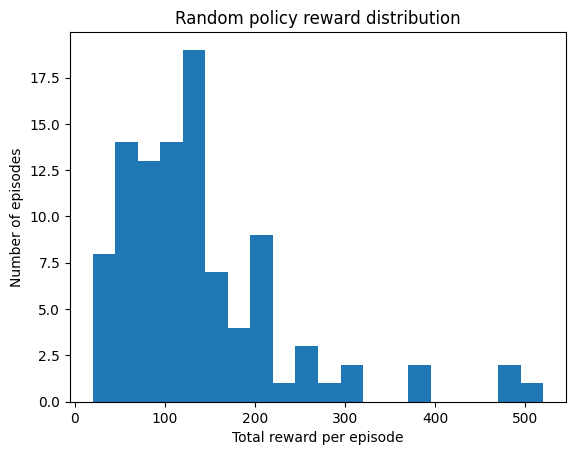

In [10]:
import matplotlib.pyplot as plt

plt.hist(episode_rewards, bins=20)
plt.xlabel('Total reward per episode')
plt.ylabel('Number of episodes')
plt.title('Random policy reward distribution')
plt.show()

# Training Agents to play Space Invaders with A2C

In [ ]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#a training loop with random actions and stacked screens
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
max_frames = 2_000_000
frames = 0
while frames < max_frames:
    if frames % 10000 == 0:
        print(f"frame #: {frames}")
    obs, info = env.reset()    #init up the environment
    history = agent.init_history(obs,Agent_config['history_length'])    #Init the history
    h_t = agent.reshape_history(history)    #reshape

    steps = 0
    total_reward = 0    #init the total reward accrued in an episode
    stop = False    #init the stopping condition
    
    agent.reset_buffer()    #reset the n-step buffer
    while not stop:    #run and episode with random actions...
        #TODO generate action
        action = agent.act(h_t)
        #TODO evolve environment
        obs, reward, done, truncated, info = env.step(action)
        steps += 1    #increment the number of steps
        frames += 4
        if steps >= agent.config['max_steps']:    #if the agent has survived to the end...
            truncated = True    #update the truncation condition
        stop = done or truncated    #update the stopping condition
        
        agent.buffer['states'].append(h_t)
        history = agent.update_history(obs,history)    #add the new screen and drop the oldest
        h_t = agent.reshape_history(history)    #reshape
        agent.buffer['actions'].append(action)
        agent.buffer['rewards'].append(reward)
        agent.buffer['next_states'].append(h_t)
        agent.buffer['dones'].append(done)
        
        total_reward += reward    #add the reward
    
        if done or truncated:    #if the episode ended...
            obs, info = env.reset()    #reset the environment
    
    #TODO compute the policy objective and value loss
    policy_objective, value_loss = agent.make_objectives_A2C()
    #TODO assemble into the objective function
    loss = -policy_objective + value_loss
    #TODO zero the gradients    
    agent.optimizer.zero_grad()
    #TODO backprop
    loss.backward()
    #TODO take a gradient step
    agent.optimizer.step()
    
env.close()    #shut the environment down
    

frame #: 0


In [ ]:
env = make_env(env_name = "ALE/SpaceInvaders-v5")
eval_returns = []
for epi in range(100):
    obs, info = env.reset()
    history = agent.init_history(obs,Agent_config['history_length'])
    h_t = agent.reshape_history(history)

    steps = 0
    total_reward = 0
    stop = False
    while not stop:
        action = agent.act(h_t)
        obs, reward, done, truncated, info = env.step(action)
        steps += 1
        if steps >= agent.config['max_steps']:
            truncated = True
        stop = done or truncated
        history = agent.update_history(obs,history)
        h_t = agent.reshape_history(history)
        total_reward += reward

    eval_returns.append(total_reward)

env.close()
print('Average return:', np.mean(eval_returns))
print('Variance of return:', np.var(eval_returns))

In [ ]:
Agent_config = {'history_length':history_length    #the number of screens to concatenate into the history
                ,'alpha':0.0001    #the learning rate
                ,'gamma':0.99    #the discount factor
                ,'beta':0.05    #the weight on entropy regularization
                ,'max_steps':200    #the max steps that an episode runs
                ,'B':5    #the episode batch size
                ,'CNNconfig':CNNconfig}


agent_higher_beta = Agent(Agent_config)

max_frames = 2_000_000
frames = 0
while frames < max_frames:
    if frames % 10000 == 0:
        print(f"frame #: {frames}")
    obs, info = env.reset()    #init up the environment
    history = agent_higher_beta.init_history(obs,Agent_config['history_length'])    #Init the history
    h_t = agent_higher_beta.reshape_history(history)    #reshape

    steps = 0
    total_reward = 0    #init the total reward accrued in an episode
    stop = False    #init the stopping condition
    
    agent_higher_beta.reset_buffer()    #reset the n-step buffer
    while not stop:    #run and episode with random actions...
        #TODO generate action
        action = agent_higher_beta.act(h_t)
        #TODO evolve environment
        obs, reward, done, truncated, info = env.step(action)
        steps += 1    #increment the number of steps
        frames += 4
        if steps >= agent_higher_beta.config['max_steps']:    #if the agent has survived to the end...
            truncated = True    #update the truncation condition
        stop = done or truncated    #update the stopping condition
        
        agent_higher_beta.buffer['states'].append(h_t)
        history = agent_higher_beta.update_history(obs,history)    #add the new screen and drop the oldest
        h_t = agent_higher_beta.reshape_history(history)    #reshape
        agent_higher_beta.buffer['actions'].append(action)
        agent_higher_beta.buffer['rewards'].append(reward)
        agent_higher_beta.buffer['next_states'].append(h_t)
        agent_higher_beta.buffer['dones'].append(done)
        
        total_reward += reward    #add the reward
    
        if done or truncated:    #if the episode ended...
            obs, info = env.reset()    #reset the environment
    
    #TODO compute the policy objective and value loss
    policy_objective, value_loss = agent_higher_beta.make_objectives_A2C()
    #TODO assemble into the objective function
    loss = -policy_objective + value_loss
    #TODO zero the gradients    
    agent_higher_beta.optimizer.zero_grad()
    #TODO backprop
    loss.backward()
    #TODO take a gradient step
    agent_higher_beta.optimizer.step()
    
env.close()    #shut the environment down
    

frame #: 0
frame #: 20000


In [ ]:
env = make_env(env_name = "ALE/SpaceInvaders-v5")
eval_returns = []
for epi in range(100):
    obs, info = env.reset()
    history = agent_higher_beta.init_history(obs,Agent_config['history_length'])
    h_t = agent_higher_beta.reshape_history(history)

    steps = 0
    total_reward = 0
    stop = False
    while not stop:
        action = agent_higher_beta.act(h_t)
        obs, reward, done, truncated, info = env.step(action)
        steps += 1
        if steps >= agent_higher_beta.config['max_steps']:
            truncated = True
        stop = done or truncated
        history = agent_higher_beta.update_history(obs,history)
        h_t = agent_higher_beta.reshape_history(history)
        total_reward += reward

    eval_returns.append(total_reward)

env.close()
print('Average return:', np.mean(eval_returns))
print('Variance of return:', np.var(eval_returns))

# Experiments: entropy regularization and frame history (Q7 & Q8)
Four A2C agents trained in parallel (one process each), then evaluated for 100 episodes:

| run | `beta` (entropy) | `history_length` |
|---|---|---|
| baseline_4f | 0.0 | 4 |
| entropy_4f | `BETA_ENT` | 4 |
| entropy_2f | `BETA_ENT` | 2 |
| entropy_1f | `BETA_ENT` | 1 |

baseline_4f vs entropy_4f isolates entropy (Q7); entropy_4f / 2f / 1f isolates frame stacking (Q8).

In [ ]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Train one A2C agent end to end -- runs inside its own process
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
import copy

def train_a2c_agent(name, beta, history_length, max_frames=2_000_000, n_eval=100,
                    seed=0, base_config=Agent_config, n_threads=3, log_every=100):
    """Train an A2C agent with the given entropy weight and frame history, then evaluate it.
        Returns a dict with the model weights, per-episode training rewards,
        per-episode mean policy entropy, and the evaluation returns.
    """
    torch.set_num_threads(n_threads)    #keep the parallel processes from fighting over cores
    torch.manual_seed(seed)
    np.random.seed(seed)

    #build the config for this run
    config = copy.deepcopy(base_config)
    config['beta'] = beta
    config['history_length'] = history_length
    config['CNNconfig']['input']['input_channels'] = history_length
    agent = Agent(config)

    env = make_env(env_name = "ALE/SpaceInvaders-v5")
    env.reset(seed=seed)

    #@@@@@@@@@@ training @@@@@@@@@@
    train_rewards, train_entropy = [], []
    frames, episode = 0, 0
    while frames < max_frames:
        obs, info = env.reset()
        history = agent.init_history(obs, history_length)
        h_t = agent.reshape_history(history)
        steps, total_reward, stop = 0, 0, False
        ep_entropy = []
        agent.reset_buffer()
        while not stop:
            with torch.no_grad():
                action_probs, _ = agent.model(torch.tensor(h_t, dtype=torch.float32))
            dist = Categorical(probs=action_probs)
            action = dist.sample().item()
            ep_entropy.append(dist.entropy().item())    #track how spread out the policy is

            obs, reward, done, truncated, info = env.step(action)
            steps += 1
            frames += 4
            if steps >= config['max_steps']:
                truncated = True
            stop = done or truncated

            agent.buffer['states'].append(h_t)
            history = agent.update_history(obs, history)
            h_t = agent.reshape_history(history)
            agent.buffer['actions'].append(action)
            agent.buffer['rewards'].append(reward)
            agent.buffer['next_states'].append(h_t)
            agent.buffer['dones'].append(done)
            total_reward += reward

        policy_objective, value_loss = agent.make_objectives_A2C()
        loss = -policy_objective + value_loss
        agent.optimizer.zero_grad()
        loss.backward()
        agent.optimizer.step()

        train_rewards.append(total_reward)
        train_entropy.append(np.mean(ep_entropy))
        episode += 1
        if episode % log_every == 0:
            print(f"{name}: episode {episode}, frames {frames}, "
                  f"avg reward (last {log_every}) = {np.mean(train_rewards[-log_every:]):.1f}, "
                  f"avg entropy = {np.mean(train_entropy[-log_every:]):.3f}", flush=True)

    #@@@@@@@@@@ evaluation @@@@@@@@@@
    eval_returns = []
    for _ in range(n_eval):
        obs, info = env.reset()
        history = agent.init_history(obs, history_length)
        h_t = agent.reshape_history(history)
        steps, total_reward, stop = 0, 0, False
        while not stop:
            action = agent.act(h_t)
            obs, reward, done, truncated, info = env.step(action)
            steps += 1
            if steps >= config['max_steps']:
                truncated = True
            stop = done or truncated
            history = agent.update_history(obs, history)
            h_t = agent.reshape_history(history)
            total_reward += reward
        eval_returns.append(total_reward)
    env.close()
    print(f"{name}: DONE -- eval avg = {np.mean(eval_returns):.2f}, var = {np.var(eval_returns):.2f}", flush=True)

    return {'config': config,
            'state_dict': agent.model.state_dict(),
            'train_rewards': np.array(train_rewards),
            'train_entropy': np.array(train_entropy),
            'eval_returns': np.array(eval_returns)}


In [ ]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Run the four experiments in parallel -- one process per run
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
BETA_ENT = 0.01    #entropy weight for the "entropy" runs
EXP_FRAMES = 2_000_000    #training budget per run (same as the main training loop)

runs = {'baseline_4f': {'beta': 0.0,      'history_length': 4},
        'entropy_4f':  {'beta': BETA_ENT, 'history_length': 4},
        'entropy_2f':  {'beta': BETA_ENT, 'history_length': 2},
        'entropy_1f':  {'beta': BETA_ENT, 'history_length': 1}}

with ProcessPoolExecutor(max_workers=len(runs), mp_context=mp.get_context('fork')) as pool:
    futures = {name: pool.submit(train_a2c_agent, name, max_frames=EXP_FRAMES, **kwargs)
               for name, kwargs in runs.items()}
    results = {name: f.result() for name, f in futures.items()}

for name, r in results.items():
    print(f"{name}: eval avg return = {r['eval_returns'].mean():.2f}, "
          f"var = {r['eval_returns'].var():.2f}, "
          f"final train entropy = {r['train_entropy'][-100:].mean():.3f}")


In [ ]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Plot learning curves, policy entropy, and eval returns
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
def smooth(x, w=100):
    return np.convolve(x, np.ones(w)/w, mode='valid')

def plot_group(names, title):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for name in names:
        r = results[name]
        axes[0].plot(smooth(r['train_rewards']), label=name)
        axes[1].plot(smooth(r['train_entropy']), label=name)
    axes[2].boxplot([results[n]['eval_returns'] for n in names], labels=names)
    axes[0].set(title='Training reward (100-ep moving avg)', xlabel='Episode', ylabel='Return')
    axes[1].set(title='Mean policy entropy per episode', xlabel='Episode', ylabel='Entropy (nats)')
    axes[1].axhline(np.log(6), ls='--', c='gray', label='uniform (ln 6)')
    axes[2].set(title='Evaluation returns (100 eps)', ylabel='Return')
    axes[0].legend(); axes[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_group(['baseline_4f', 'entropy_4f'], 'Q7: effect of entropy regularization (4 frames)')
plot_group(['entropy_1f', 'entropy_2f', 'entropy_4f'], f'Q8: effect of frame history (beta = {BETA_ENT})')
